# AI Programming Project

# Welcome to our AI Programming Project! 
Here, we’ll be exploring the world of streaming content using a subset of the Netflix Titles Dataset (netflix_titles_subset.csv). This dataset gives us a great snapshot of the movies and TV shows available on the platform.

Our goal is to dig into this data and do some data processing, analysis and visualisation! 

Before we dive into the code, let’s take a quick look at what information we have in each column:

# Column Description:


*   `show_id`: This column represents a unique identifier for each title.


*   `type`: This column represents the classification of the content (Movie or TV Show).


*   `title`: This column represents the official name of the content.


*   `director`: This column represents the director(s) of the content.


*   `cast`: This column represents a comma-separated list of the main actors and actresses.


*   `country`: This column represents the country or countries of production.


*   `date_added`: This column represents the date the content was added to Netflix.


*   `release_year`: This column represents the original year the content was released.


*   `rating`: This column represents the maturity rating of the content.


*   `duration`: This column represents the length of the content (minutes for Movies, seasons for TV Shows).


*   `listed_in`: This column represents the genres or categories of the content.


*   `description`: This column represents a brief summary of the content.

# Our Project Team's Information


Here is a table that shows the team members names, their student IDs, and their assigned tasks.

| Student Name | ID | Tasks |
| :--- | :---: | :--- |
| Sara Aljohani | 4555479 | Validating data & Grouping and aggregating & Normalizing data & Line graph and Bar chart and Heatmaps & Checking data |
| Arwa Almahyawi | 4555781 | Tokenizing text data & Correlation & Histogram |
| Afnan Lutfullah | 4556754 | Reformatting data & Finding central values & Scatter plot and pie chart |
| Jory Alhindi | 4554425 | Filling missing values & Removing Duplicate Records & Finding common words & Normalizing data & Pie chart |

# Data Processing:


*  `Problem 1`: To ensure `release_year` data validity, The data was identified and flagged any missing, non-numeric, or out-of-range (1920–2021) values as invalid.

*  `Problem 2`: The `listed_in` column contains multiple categories combined in a single cell and separated by commas, making the data difficult to analyze or group. Reformat the column by preparing it for structured splitting into separate genre fields.

*  `Problem 3`: If the dataset had duplicate titles, duplicates will be removed using drop_duplicates to keep only the first record only if the title was repeated.

*  `Problem 4`: Some columns contained missing values that could affect later analysis, so all empty entries were filled with the word “Unknown” to keep the data consistent.
 
*  `Problem 5`: The column `date_added` was stored as text, so it was converted into a proper datetime format using pd.to_datetime().

*  `Problem 6`: The `listed_in` column needed to be normalized for later visualization.

*  `Problem 7`: The `country` column included multiple countries in single cells, so values were split by commas to separate them.

*  `Problem 8`: Extra spaces in `country` names were removed to ensure clean and uniform entries.


# Data Analysis:

*  `Problem 1`: The problem is finding repeated words in descriptions column, so the five most frequently occurring words were extracted from the description column.
*  `Problem 2`: For a better understanding of the dataset, the entries in the `type` column were grouped to count the total number of Movies and TV Shows.

*  `Problem 3`: Determine the average duration of content (Movies and TV Shows) to understand the central tendency of content length on the platform.


*  `Problem 4`: Country frequencies were counted to determine how often each country appeared in the dataset.

*  `Problem 5`: Numerical columns `duration` and `release_year` were analyzed by calculating correlation.
  

# Data Visualization:

*  `Problem 1`: The top 10 Netflix genres from the column `listed_in` were visualized using a horizontal bar chart to compare the number of titles in each genre.

*  `Problem 2`: Generate a Scatter Plot to explore the visual relationship between movie's `duration` and its `release_Year`, to identify any trends over time.

*  `Problem 3`: A comparison between content `type` was needed, so a pie chart was created to show the percentage of Movies versus TV Shows.

*  `Problem 4`: Create a Pie Chart to visualize the percentage distribution of all audience `rating` across the dataset.

*  `Problem 5`: To understand how movie durations vary in the dataset and to identify which duration ranges are most common, a histogram was created to show the frequency distribution of movie durations, making it easy to visually determine the most typical movie lengths.

*  `Problem 6`: The `release_year` of `type` --> Movies and TV Shows were visualized with a Line Graph to show trends in Netflix content over time.
  

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from wordcloud import WordCloud

In [20]:
netflix = pd.read_csv('netflix_titles_subset.csv')

For a better understanding of the dataset we are handling:

In [21]:
netflix.shape

(800, 12)

In [22]:
netflix.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [38]:
netflix.describe

<bound method NDFrame.describe of     show_id     type                  title          director  \
0        s1    Movie   Dick Johnson Is Dead   Kirsten Johnson   
1        s2  TV Show          Blood & Water               NaN   
2        s3  TV Show              Ganglands   Julien Leclercq   
3        s4  TV Show  Jailbirds New Orleans               NaN   
4        s5  TV Show           Kota Factory               NaN   
..      ...      ...                    ...               ...   
795    s796  TV Show          Happy Endings               NaN   
796    s797    Movie       Hostel: Part III     Scott Spiegel   
797    s798    Movie               I Am Sam     Jessie Nelson   
798    s799    Movie             Love Jones  Theodore Witcher   
799    s800    Movie    Million Dollar Baby    Clint Eastwood   

                                                  cast        country  \
0                                                  NaN  United States   
1    Ama Qamata, Khosi Ngema, Gail Maba

In [23]:
netflix.dtypes

show_id         object
type            object
title           object
director        object
cast            object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
description     object
dtype: object

determining whether there are null values in the data or not:

In [24]:
netflix.isnull().sum()

show_id           0
type              0
title             0
director        265
cast             80
country         256
date_added        0
release_year      0
rating            0
duration          0
listed_in         0
description       0
dtype: int64

Heatmap before cleaning:

<Axes: >

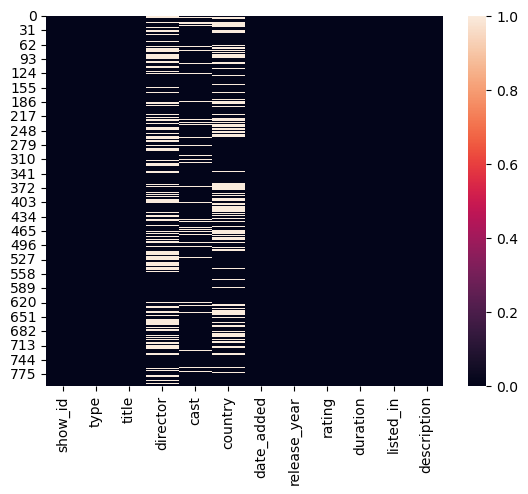

In [25]:
sns.heatmap(netflix.isnull())

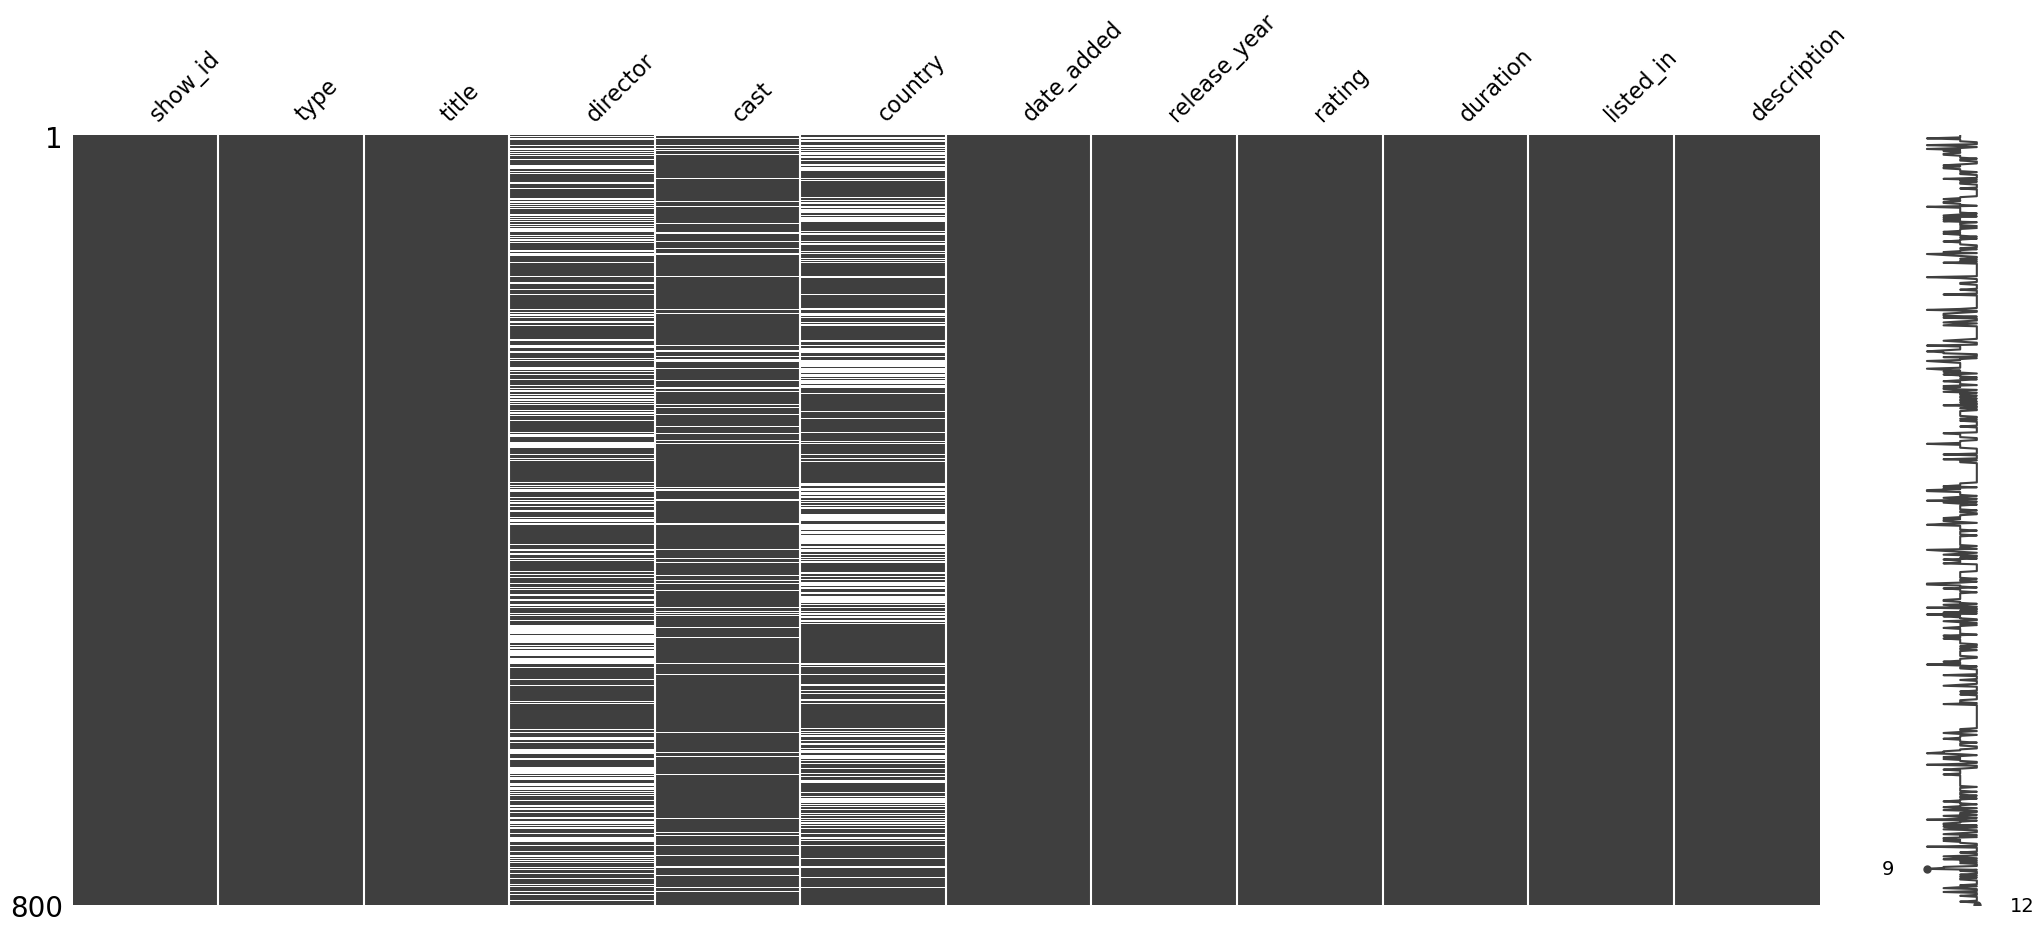

In [26]:
msno.matrix(netflix)
plt.show()

We can now clearly see that there are null values in the columns: `director` , `cast` , `country`

# Below is the full OOP code that combines all the tasks completed in this project:

================== DATA PROCESSING ==================
The invalid years are:
Empty DataFrame
Columns: [show_id, type, title, director, cast, country, date_added, release_year, rating, duration, listed_in, description]
Index: []
---------------------------------------------------------
The Dataset after reformatting listed_in column:
                   title                  genre1                  genre2  \
0   Dick Johnson Is Dead           Documentaries                     N/A   
1          Blood & Water  International TV Shows               TV Dramas   
2              Ganglands          Crime TV Shows  International TV Shows   
3  Jailbirds New Orleans              Docuseries              Reality TV   
4           Kota Factory  International TV Shows       Romantic TV Shows   

                  genre3  
0                    N/A  
1           TV Mysteries  
2  TV Action & Adventure  
3                    N/A  
4            TV Comedies  
----------------------------------------------

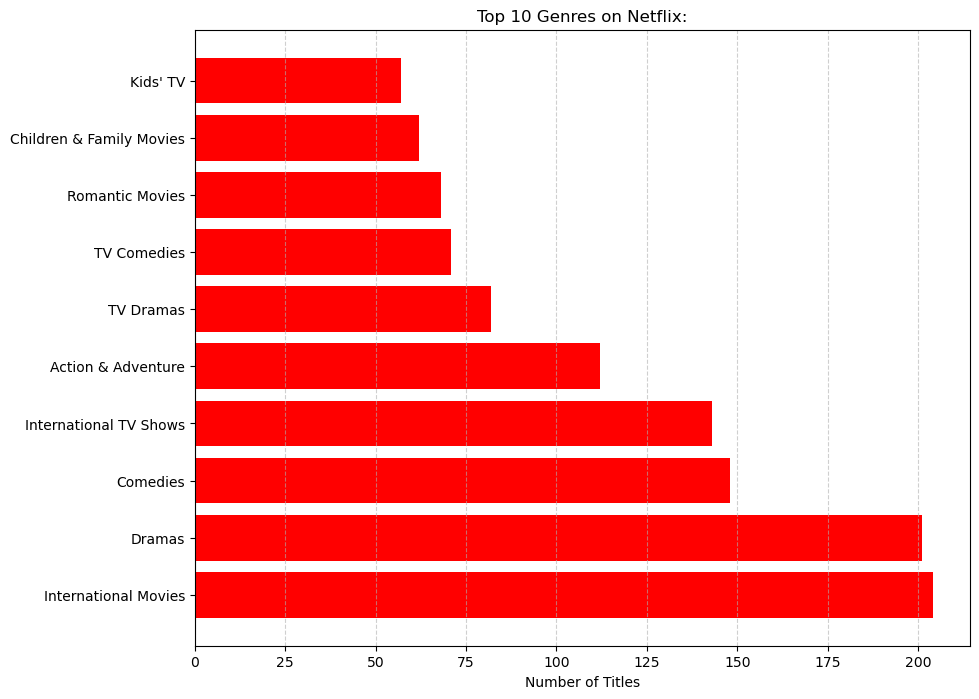

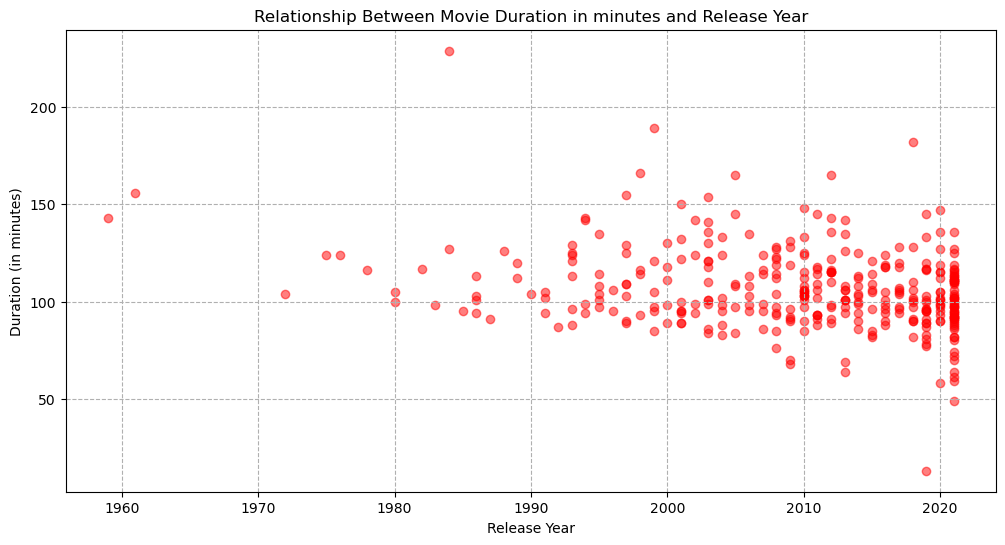

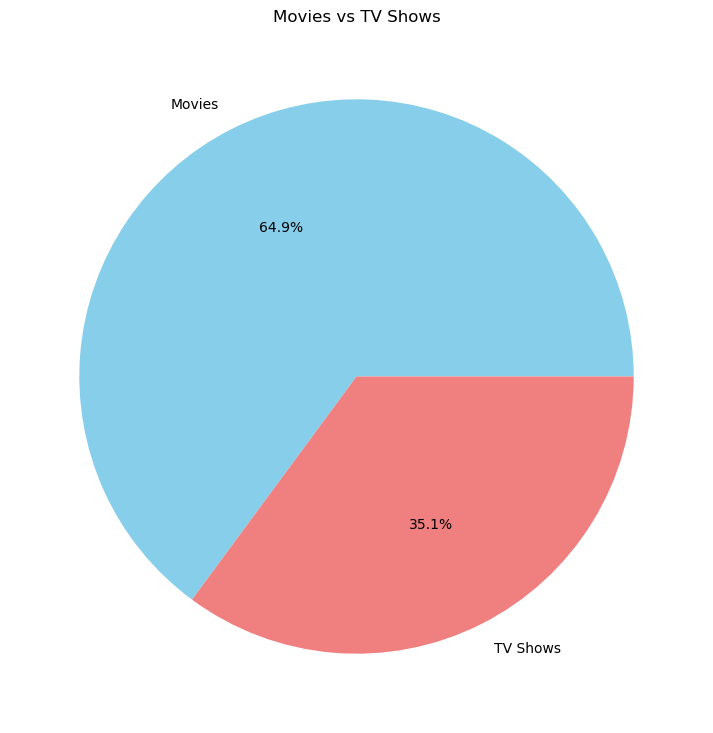

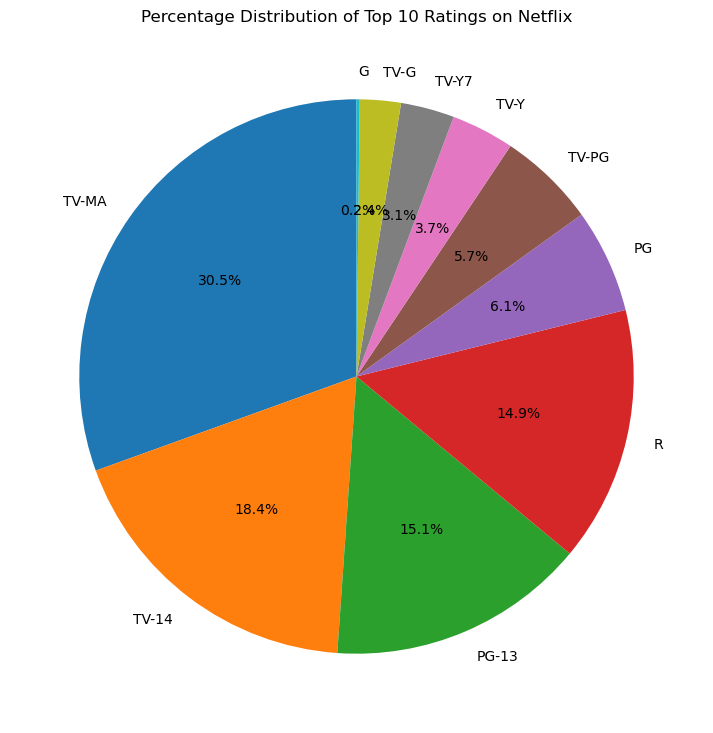

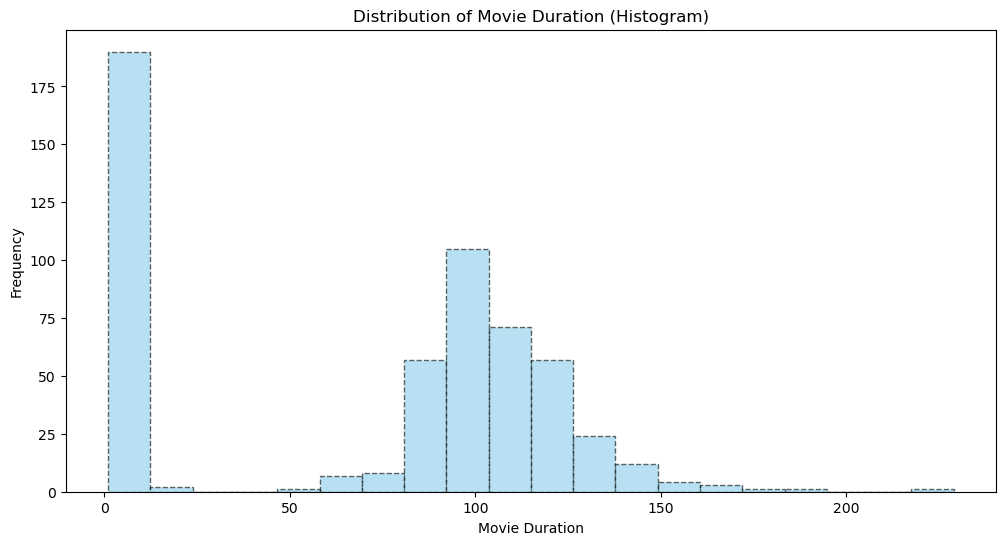

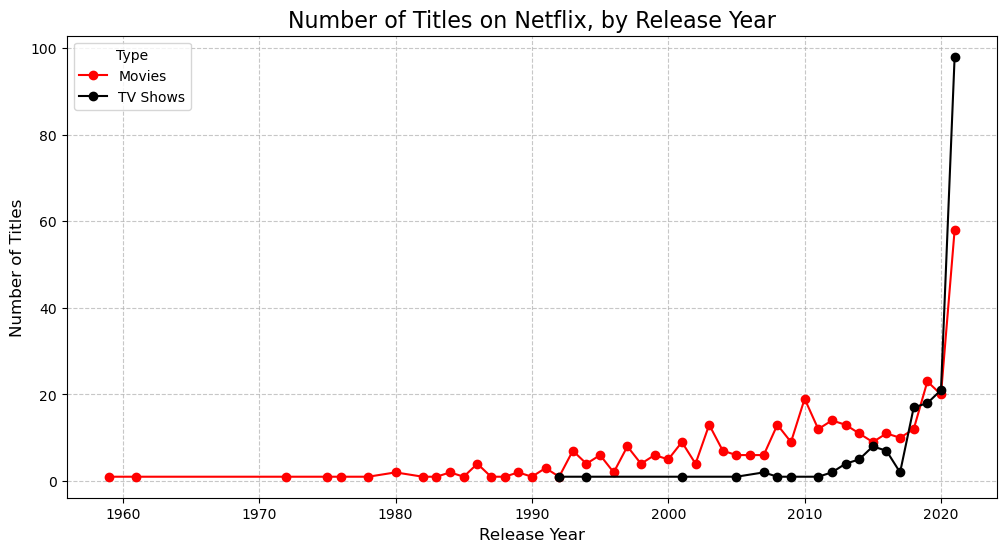

In [40]:
class Project:
    
    # DATA PROCESSING    
    def data_Processing(self, netflix):
        
        # Task 1: validating release_year (Sara)
        # Convert to numeric, invalid entries become NaN
        years = pd.to_numeric(netflix['release_year'])
        # Find years that dont make sence
        validate_years = netflix[(years < 1920) | (years > 2021) | (years.isna())]
        print("The invalid years are:")
        print(validate_years)

        print("---------------------------------------------------------")
        
        # Task 2: reformatting listed_in column (Afnan)
        # Split the 'listed_in' column into up to 3 genres
        genres_split = netflix['listed_in'].str.split(', ', expand=True)

        # Create only genre1, genre2, genre3
        for i in range(3):
            if i in genres_split.columns:
                netflix[f'genre{i+1}'] = genres_split[i].str.strip()
            else:
                netflix[f'genre{i+1}'] = "N/A"

        # Replace empty strings AND NaN with "N/A"
        genre_columns = ['genre1', 'genre2', 'genre3']
        netflix[genre_columns] = (
        netflix[genre_columns].replace("", "N/A").fillna("N/A"))

        print("The Dataset after reformatting listed_in column:")
        print(netflix[['title', 'genre1', 'genre2', 'genre3']].head())

        
        print("---------------------------------------------------------")
        
        # Task 3: removing duplicates (Jory)
        # Deleting duplicated titles if found:
        netflix = netflix.drop_duplicates(subset=['title'])  
        print("Duplicated titles were removed from the 'title' column.")

        print("---------------------------------------------------------")
        
        # Task 4: filling missing values (Jory)
        # Making for loop to fill every missing value in every column except for 'duration' and 'country' columns:
        for col in netflix.columns:
            if col != "duration" and col != "country":
               netflix[col] = netflix[col].fillna("Unknown")

        print("The empty blanks are filled with 'Unknown': ")
        # Printing the result:
        print(netflix)

        print("---------------------------------------------------------")
        
        # Task 5: converting 'date_added' to datetime (Jory)
        # Converting to dataTime by using pd.to_datatime, and if any error occuor convert it to NAT
        netflix["date_added"] = pd.to_datetime(netflix["date_added"], errors="coerce")
        print("The column 'date_added' after converting it to datetime format:")
        #print the result:
        print(netflix.head())

        print("---------------------------------------------------------")
        
        # Task 6: normalizing the listed_in column to prepare for visualization (Sara)
        all_genres = []
        for value in netflix['listed_in']:
            all_genres.extend(value.split(', '))
            
        genre_counts = pd.Series(all_genres).value_counts()
        top_10_genres = genre_counts.head(10).reset_index()
        top_10_genres.columns = ['Genre', 'Count']
        print("Top 10 genres:")
        print(top_10_genres)

        print("---------------------------------------------------------")
        
        # Task 7: Clean country column (Arwa) 
        netflix['country'] = netflix['country'].str.title()
        # Remove rows where the country column is missing
        netflix = netflix.dropna(subset=['country'])
        # Split the country column into multiple columns 
        clean_country = netflix['country'].str.split(",", expand=True)
        netflix['country1'] = clean_country[0].str.strip()
        netflix['country2'] = clean_country[1].str.strip()
        netflix['country3'] = clean_country[2].str.strip()
        netflix['country4'] = clean_country[3].str.strip()
        netflix['country5'] = clean_country[4].str.strip()
        netflix['country6'] = clean_country[5].str.strip()
        # Store the list of new country columns 
        self.columns_list = ['country1','country2','country3','country4','country5','country6']
        # Replace missing values with 'N/A'
        netflix[self.columns_list] = netflix[self.columns_list].fillna("N/A")
        netflix.drop(columns=['country'],inplace=True)
        print(netflix.head())

        print("---------------------------------------------------------")
        
        # Task 8: Clean the duration column (Arwa)
        netflix['duration_clean'] = netflix['duration'].str.replace("min", "", regex=False)
        netflix['duration_clean'] = netflix['duration_clean'].str.replace("Season", "", regex=False)
        netflix['duration_clean'] = netflix['duration_clean'].str.replace("s", "", regex=False)
        print(netflix[self.columns_list].head())
        print(netflix[['duration','duration_clean']].head())

        netflix.to_csv("netflix_cleaned.csv", index=False)
        return netflix, top_10_genres


    # DATA ANALYSIS
    def data_Analysis(self, netflix):
        
        # Task 1: finding the most 5 frequently occurring words (Jory)
        # Converting decriotion col to string, then join them in one text, then split them into a list of words:
        words = " ".join(netflix['description'].astype(str)).split()
        # Then converting list to series and use 'value_counts(), head()' to count word frequancies and keep only top 5:
        words_count = pd.Series(words).value_counts().head(5)
        
        print("The most 5 frequently occurring words:")
        # Print each word and its count with for loop:
        for word, count in words_count.items():  
            print(word, "->", count)
            
        print("---------------------------------------------------------")
        
        # Task 2: Grouping & Aggregating type column (Sara) 
        type_counts = netflix.groupby('type').agg(count=('type', 'count'))

        print("Number of Movies and TV Shows:")
        print(type_counts)


        print("---------------------------------------------------------")
        
        # Task 3: (Afnan)
        # Filter only movies from the dataset
        movies = netflix[netflix['type'] == 'Movie'].copy()
        # Remove ' min' from the duration column
        movies['duration'] = movies['duration'].str.replace(' min', '', regex=False)
        # Convert duration to float to allow NaN values without errors
        movies['duration'] = movies['duration'].astype(float)  # instead of int
        # Filter only TV shows from the dataset
        shows = netflix[netflix['type'] == 'TV Show'].copy()
        # Remove 'Seasons' or 'Season' from the duration column
        shows['duration'] = shows['duration'].str.replace(' Seasons', '', regex=False)
        shows['duration'] = shows['duration'].str.replace(' Season', '', regex=False)
        # Convert duration to float
        shows['duration'] = shows['duration'].astype(float)  # instead of int
        # Calculate statistics for movies
        movie_mean = movies['duration'].mean()
        movie_median = movies['duration'].median()
        movie_mode = movies['duration'].mode().iloc[0]
        # Calculate statistics for TV shows
        show_mean = shows['duration'].mean()
        show_median = shows['duration'].median()
        show_mode = shows['duration'].mode().iloc[0]
        # Print the results
        print(f"1. Movie Duration minutes:")
        print(f"   Mean: {movie_mean:.2f}")
        print(f"   Median: {movie_median}")
        print(f"   Mode: {movie_mode}")
        print("\n2. TV Show Seasons:")
        print(f"   Mean: {show_mean:.2f}")
        print(f"   Median: {show_median}")
        print(f"   Mode: {show_mode}")

        print("---------------------------------------------------------")
        
        # Task 4:(Arwa)
        # Count total number of country entries (excluding N/A)
        total = (netflix[self.columns_list] != 'N/A').sum().sum()
        print(f"\nTotal country values: {total}")
 
        # Dictionary to store country frequency
        country_counts = {}

        # Loop through each country column
        for col in self.columns_list:
            for value in netflix[col]:
                if value != "N/A":
                    country_counts[value]=country_counts.get(value,0)+1
                  
        print("\nCountry Frequency:")
        for country, count in country_counts.items():
            print(f"{country}: {count}")

        print("---------------------------------------------------------")
        
        # Task 5: Compute the correlation between duration and release year (Arwa)
        corr = movies['duration_clean'].astype(float).corr(movies['release_year'])
        print(f"\nCorrelation between duration and release year: {corr:.2f}")

        return movies, shows


    # DATA VISUALIZATION        
    def data_Visualization(self, top_10_genres, movies, netflix):
        
        # Task 1: create a bar chart for the top 10 in the column listed_in (Sara)
        plt.figure(figsize=(10, 8))
        plt.barh(top_10_genres['Genre'], top_10_genres['Count'], color='red')
        # Add labels and title
        plt.xlabel('Number of Titles')
        plt.title('Top 10 Genres on Netflix:')
        plt.grid(axis='x', linestyle='--', alpha=0.6)
        plt.show()
        
        # Task 2: create a scatter plot for the relationship between release_year and duration (Afnan)
        # Set the figure size
        plt.figure(figsize=(12, 6))
        # Create a scatter plot
        plt.scatter(
        # x-axis: release year of the movie
        movies['release_year'], 
        # y-axis: duration in minutes
        movies['duration'],     
        alpha=0.5,                
        color='red'              
        )
        # Add title and axis labels
        plt.title('Relationship Between Movie Duration in minutes and Release Year')
        plt.xlabel('Release Year')
        plt.ylabel('Duration (in minutes)')
        # Add a grid with dashed lines
        plt.grid(True, linestyle='--')
        # Display the plot
        plt.show()

        # Task 3: pie chart for types (Jory)
        # Count rows that have 'Movie'
        movie_count = (netflix["type"] == "Movie").sum()
        # Count rows that have 'TV Show'
        show_count  = (netflix["type"] == "TV Show").sum()
        sizes = [movie_count, show_count]
        labels = ["Movies", "TV Shows"]
        colors = ["skyblue", "lightcoral"]
        plt.figure(figsize=(9,9))
        plt.pie(sizes, labels=labels, autopct="%1.1f%%", colors=colors)
        plt.title("Movies vs TV Shows")
        plt.show()

        # Task 4: Count the occurrences of each rating (Afnan) 
        rating_counts = netflix['rating'].value_counts().head(10)
        plt.figure(figsize=(9, 9))
        # Create a pie chart to visualize the percentage distribution of the top 10 ratings
        plt.pie(
            rating_counts,  
            # Labels for each slice 
            labels=rating_counts.index,  
            # Display percentage values 
            autopct='%1.1f%%',  
            # Rotate the start angle 
            startangle=90,  
)
        # Title of the chart
        plt.title('Percentage Distribution of Top 10 Ratings on Netflix')
        # Show the pie chart
        plt.show()

    
        # Task 5: Create a histogram to show the distribution of movie duration (Arwa)
        # width =10 ,  height = 6
        plt.figure(figsize=(12,6))
        # plotting the data
        plt.hist(netflix['duration_clean'].astype(float), bins=20, color='skyblue', edgecolor='black',linestyle='--', alpha=0.6)
        # label on the y-axis
        plt.xlabel("Movie Duration")
        # label on the x-axis
        plt.ylabel("Frequency")
        # Adding title
        plt.title("Distribution of Movie Duration (Histogram)")
        plt.show()
        
        # Task 6: create a line graph to show the relationship between type and release_year (Sara)
        # Group by 'release_year' and 'type', and count the titles
        content_released_yearly = netflix.groupby(['release_year', 'type']).agg(count=('type', 'count')).reset_index()
        # Separate data for plotting
        movie_data = content_released_yearly[content_released_yearly['type'] == 'Movie']
        show_data = content_released_yearly[content_released_yearly['type'] == 'TV Show']
        # Plot the result (Number of Titles Released Per Year)
        plt.figure(figsize=(12, 6))
        plt.plot(movie_data['release_year'], movie_data['count'], label='Movies', color='red', marker='o') 
        plt.plot(show_data['release_year'], show_data['count'], label='TV Shows', color='black', marker='o') 
        plt.title('Number of Titles on Netflix, by Release Year', fontsize=16)
        plt.xlabel('Release Year', fontsize=12)
        plt.ylabel('Number of Titles', fontsize=12)
        plt.legend(title='Type')
        plt.grid(True, linestyle='--', alpha=0.7)
        plt.show()
        
        return
        
# MAIN FUNCTION
def main():

    # Load the dataset
    netflix = pd.read_csv('netflix_titles_subset.csv')


    # Instantiate the project class
    project_instance = Project()

    # Data Processing
    print("================== DATA PROCESSING ==================")
    netflix_processed, top_10_genres = project_instance.data_Processing(netflix.copy())

    # Data Analysis
    print("\n================== DATA ANALYSIS ==================")
    movies_analyzed, shows_analyzed = project_instance.data_Analysis(netflix_processed.copy())
    
    # Data Visualization
    print("\n================== DATA VISUALIZATION ==================")
    project_instance.data_Visualization(top_10_genres, movies_analyzed, netflix_processed)


if __name__ == "__main__":
    main()

# so now after we have seen the output here is the conclusion:
- There were no invalid years in the Dataset, thats why the output shows 'Empty DataFrame'.
- There are more movies than TV shows in the Dataset, Almost twice as many.
- In the visualization of Genres, A few genres appear much more often than others, such as: International Movies and Dramas, showing what type of content Netflix focuses on the most.
- In the Line Graph, The number of titles generally increases over the years, especially movies.


Heatmap after cleaning:
- We can notice the extra columns added to the dataset (country2,3,4,5,6), (genre1,2,3), (duration_clean)

<Axes: >

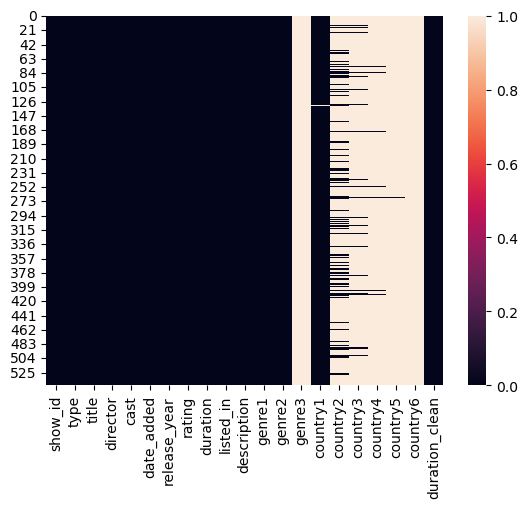

In [28]:
# Load cleaned dataset 
netflix_cleaned = pd.read_csv("netflix_cleaned.csv")
sns.heatmap(netflix_cleaned.isnull())

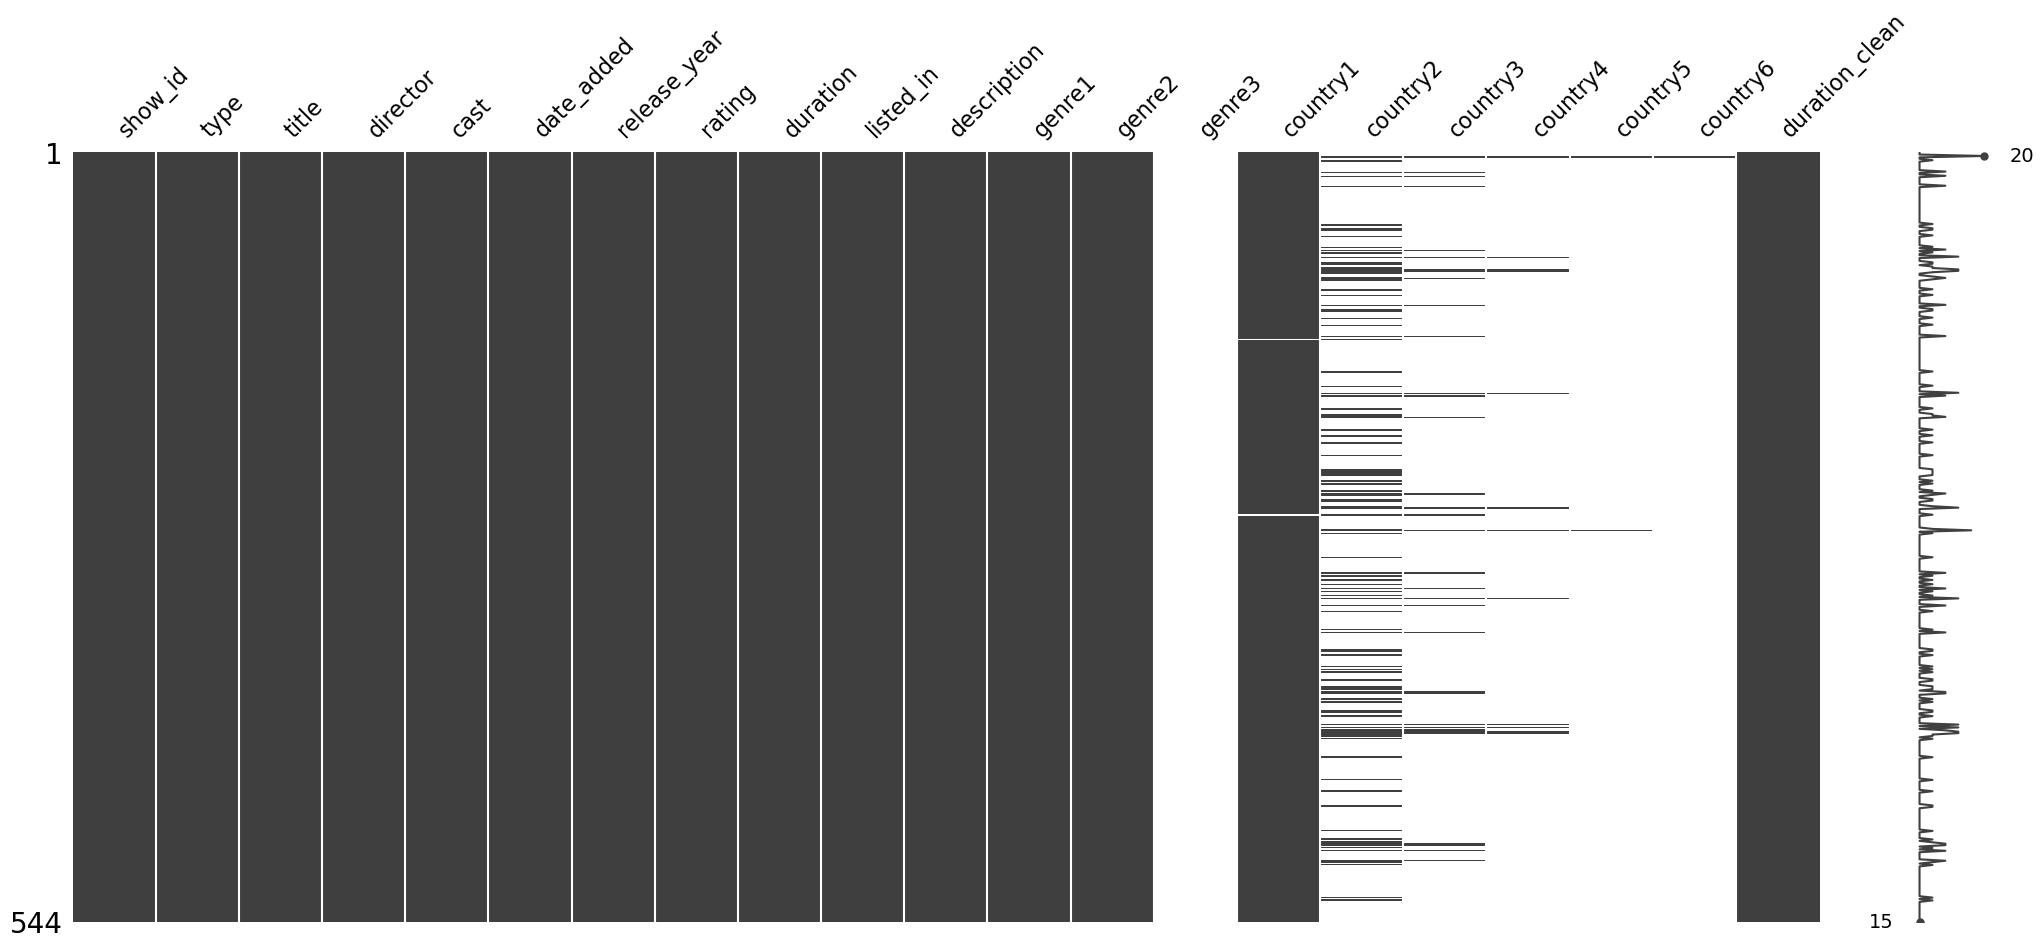

In [29]:
netflix_cleaned = pd.read_csv("netflix_cleaned.csv")
msno.matrix(netflix_cleaned)
plt.show()

This graph is a word cloud representing a collection of words from the `listed_in` column, it creates a visual representation where:

More frequent genres appear larger, such as "International Movies, TV Shows"

Less frequent genres appear smaller, such as "TV International, British TV"

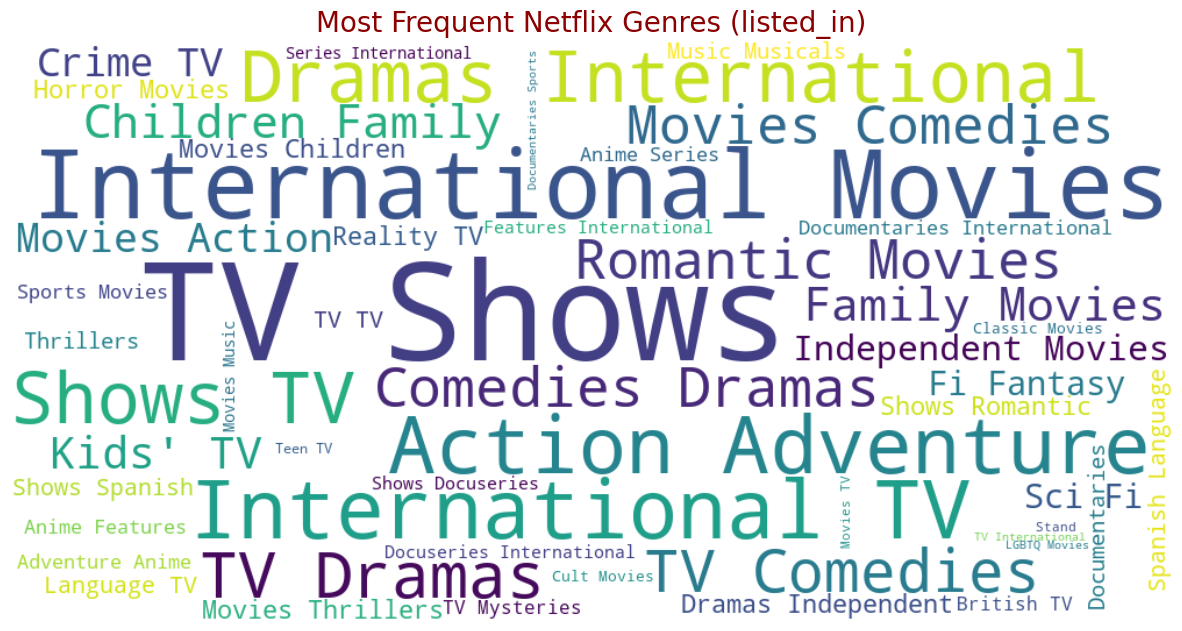

In [30]:
#WoedCloud representation (Sara)
text = netflix['listed_in']
# Join all the individual genre strings into one large string
combined_text = ' '.join(text)

# Define the WordCloud parameters
wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    colormap='viridis',
    min_font_size=10
).generate(combined_text)


# Display
plt.figure(figsize=(15, 8))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off") # Turn off axis labels and ticks
plt.title('Most Frequent Netflix Genres (listed_in)', fontsize=20, color='darkred')
plt.show()